# Derived vs catalogued amplitude: a sample of classical Cepheids
Question: for a sample of classical Cepheids, do V amplitudes derived from AAVSO observations agree with the catalogued VSX V amplitude, and by how much do they differ?

## Selection rules (written before looking at any results)
- Variability type DCEP in VSX, with a V-band magnitude range and a period listed.
- Period between 3 and 15 days (so 2024-2025 covers at least about 50 cycles).
- Bright enough to be well observed: brighter than V = 8 at maximum (threshold may change after seeing observation counts, but not after seeing amplitude results).
- Observations: Johnson V, 2024-01-01 to 2025-12-31, same download settings as del Cep.
- Keep a star only if it has at least N observations (N to be fixed after seeing counts).
- The same pipeline (check-star screening, order-3 Fourier fit, bootstrap) is applied to every star.
- Scope: conclusions apply only to bright, well-observed classical Cepheids.
- Screening (revised 2026-10-14): check-star data are missing for most stars, so no check-star screening is used for any star. Outliers are removed using a robust rule, fixed before looking at amplitudes.
- Minimum observations: a star is kept only if it has at least N_obs usable rows in 2024-2025 (N_obs fixed after seeing row counts, before seeing amplitudes).
- N_obs = 80 Johnson V rows in 2024-2025, fixed 2026-10-15 before any amplitude results for these stars
- Screening (final, 2026-10-15): 
(1) drop rows more than 1.0 mag from the star's median magnitude; (2) fit an order-3 Fourier series at the VSX period; (3) drop rows with |residual| > 5 x 1.4826 x MAD; (4) refit once on the remaining rows. Applied identically to all 8 stars.

In [ ]:
import pandas as pd
v = pd.read_csv("../data/raw/vsx_dcep_search_20261014.csv")
print(v.shape)
print(v.columns.tolist())
print(v.head(5).to_string())

(57, 8)
['Name', 'AUID', 'Coords', 'Const', 'Type', 'Period', 'Mag', 'Observations']
                      Name         AUID                   Coords Const  Type     Period               Mag  Observations
0                    U Aql  000-BCT-642  19 29 21.36 -07 02 38.7   Aql  DCEP   7.024110     6.08 - 6.86 V          6281
1                   TT Aql  000-BCF-419  19 08 13.75 +01 17 55.2   Aql  DCEP  13.754900     6.53 - 7.65 V         12136
2                  eta Aql  000-BCT-763  19 52 28.37 +01 00 20.4   Aql  DCEP   7.176790     3.49 - 4.30 V         36424
3  ZTF J192152.00+150346.9  000-BPQ-419  19 21 52.01 +15 03 47.0   Aql  DCEP   8.777444  16.582 (0.500) g           471
4                   RT Aur  000-BBL-373  06 28 34.09 +30 29 34.9   Aur  DCEP   3.728240     5.00 - 5.82 V         13348


In [2]:
import re
import numpy as np
import pandas as pd

def parse_mag(s):
    """Parse VSX Mag strings like '6.08 - 6.86 V'. Returns (bright, faint, band) or NaN."""
    m = re.match(r"^\s*([\d.]+)\s*-\s*([\d.]+)\s+([A-Za-z]+)\s*$", str(s))
    if m:
        return float(m.group(1)), float(m.group(2)), m.group(3)
    return np.nan, np.nan, None

v[["mag_bright", "mag_faint", "band"]] = v["Mag"].apply(lambda s: pd.Series(parse_mag(s)))
v["vsx_amp"] = v["mag_faint"] - v["mag_bright"]

# 1. parsing results
print("band counts:")
print(v["band"].value_counts(dropna=False))
print()
print("rows that are not V-band or did not parse:")
print(v[v["band"] != "V"][["Name", "Mag", "band"]].to_string())
print()
print("variability types:")
print(v["Type"].value_counts())

# 2. do the period and brightness cuts hold?
print()
print("period summary:")
print(v["Period"].describe().round(3))
print()
vv = v[v["band"] == "V"]
print(len(vv), "rows with a V-band range")
print(vv["mag_bright"].describe().round(2))

# 3. del Cep, to check the hand-typed values from notebook 05
print()
print("del Cep rows:")
print(v[v["Name"].str.contains("del Cep", case=False)].to_string())

band counts:
band
V      42
NaN    15
Name: count, dtype: int64

rows that are not V-band or did not parse:
                       Name                Mag band
3   ZTF J192152.00+150346.9   16.582 (0.500) g  NaN
15                   TY Cru  11.021 (0.380) Ic  NaN
17                V2525 Cyg   12.983 (0.573) g  NaN
18    WISE J195222.3+421516  10.981 (0.153) W1  NaN
20    WISE J054003.9-672352  13.472 (0.165) W1  NaN
23                LMC V0792     14.28 (1.35) V  NaN
24                   AA Mon   13.432 (0.868) g  NaN
25                   FI Mon   12.473 (0.544) r  NaN
30                   CV Ori  11.734 (0.575) Ic  NaN
33             NSVS 1951077   12.755 (0.512) g  NaN
35                   CM Pup   13.528 (0.609) r  NaN
36                   HW Pup  10.508 (0.617) Ic  NaN
38  ZTF J193156.28+183312.4   16.195 (0.745) g  NaN
47         OGLE-BLG-CEP-076  13.833 (0.575) Ic  NaN
48         [DMM2015] VVV-17    12.13 (0.25) Ks  NaN

variability types:
Type
DCEP    57
Name: count, dtype: int6

In [3]:
sel = v[v["band"] == "V"].copy()
print("V-band range rows:", len(sel))

sel = sel[(sel["Period"] >= 3) & (sel["Period"] <= 15)]
print("after period 3-15 d:", len(sel))

sel = sel[sel["mag_bright"] < 8]
print("after V < 8 at maximum:", len(sel))

print()
print(v["Type"].value_counts().to_string())
print()
print(sel[["Name", "AUID", "Period", "mag_bright", "mag_faint", "vsx_amp", "Observations"]]
      .sort_values("Observations", ascending=False).to_string())

V-band range rows: 42
after period 3-15 d: 42
after V < 8 at maximum: 42

Type
DCEP    57

         Name         AUID     Period  mag_bright  mag_faint  vsx_amp  Observations
10    del Cep  000-BCQ-471   5.366290        3.49       4.36     0.87         70654
2     eta Aql  000-BCT-763   7.176790        3.49       4.30     0.81         36424
22    zet Gem  000-BBM-362  10.149806        3.62       4.18     0.56         23925
37      S Sge  000-BCW-946   8.382086        5.24       6.04     0.80         16386
55      T Vul  000-BCM-658   4.435380        5.41       6.09     0.68         14369
4      RT Aur  000-BBL-373   3.728240        5.00       5.82     0.82         13348
1      TT Aql  000-BCF-419  13.754900        6.53       7.65     1.12         12136
16     SU Cyg  000-BCV-605   3.845570        6.44       7.22     0.78         11064
26      R Mus  000-BCW-450   7.510400        5.93       6.73     0.80          9854
19    bet Dor  000-BCV-841   9.842675        3.41       4.08     0.67

In [4]:
for n in [100, 500, 1000, 2000]:
    print(f"VSX observations >= {n}: {(sel['Observations'] >= n).sum()} stars")

print()
print(sel["Observations"].describe().round(0))
print()
print(sel[["Name", "AUID", "Observations"]].sort_values("Observations").head(12).to_string())

VSX observations >= 100: 40 stars
VSX observations >= 500: 35 stars
VSX observations >= 1000: 34 stars
VSX observations >= 2000: 23 stars

count       42.0
mean      7201.0
std      12329.0
min         20.0
25%       1254.0
50%       3031.0
75%       8536.0
max      70654.0
Name: Observations, dtype: float64

         Name         AUID  Observations
9   V0737 Cen  000-BCV-337            20
32  V0440 Per  000-BCW-792            64
54     BG Vel  000-BFP-207           139
34     AP Pup  000-BCW-886           308
11     AX Cir  000-BCV-480           371
7      ER Car  000-BBS-007           443
50  V0636 Sco  000-BCX-146           480
29     BF Oph  000-BBY-473           957
45     BB Sgr  000-BCD-416          1029
5      CK Cam  000-BBH-895          1041
28      S Nor  000-BCW-466          1242
43     YZ Sgr  000-BCD-363          1288


In [5]:
N = 2000
targets = (sel[sel["Observations"] >= N]
           [["Name", "AUID", "Period", "mag_bright", "mag_faint", "vsx_amp", "Observations"]]
           .sort_values("Observations", ascending=False)
           .reset_index(drop=True))
print(len(targets), "stars selected with N =", N)
print(targets.to_string())

targets.to_csv("../data/processed/cepheid_targets.csv", index=False)

23 stars selected with N = 2000
       Name         AUID     Period  mag_bright  mag_faint  vsx_amp  Observations
0   del Cep  000-BCQ-471   5.366290        3.49       4.36     0.87         70654
1   eta Aql  000-BCT-763   7.176790        3.49       4.30     0.81         36424
2   zet Gem  000-BBM-362  10.149806        3.62       4.18     0.56         23925
3     S Sge  000-BCW-946   8.382086        5.24       6.04     0.80         16386
4     T Vul  000-BCM-658   4.435380        5.41       6.09     0.68         14369
5    RT Aur  000-BBL-373   3.728240        5.00       5.82     0.82         13348
6    TT Aql  000-BCF-419  13.754900        6.53       7.65     1.12         12136
7    SU Cyg  000-BCV-605   3.845570        6.44       7.22     0.78         11064
8     R Mus  000-BCW-450   7.510400        5.93       6.73     0.80          9854
9   bet Dor  000-BCV-841   9.842675        3.41       4.08     0.67          9757
10    U Vul  000-BCH-251   7.990676        6.73       7.54     0.8

In [6]:
import glob, os

for f in sorted(glob.glob("../data/raw/aavso_cepheids/*.csv")):
    d = pd.read_csv(f)
    has_comments = "comments" in d.columns
    n_check = d["comments"].astype(str).str.contains("KMAGSTD").sum() if has_comments else 0
    print(os.path.basename(f))
    print("  rows:", len(d), "| columns:", d.shape[1], "| has comments column:", has_comments,
          "| rows with check-star values:", n_check)

000-BBL-373_RT_Aur.csv


  rows: 1 | columns: 19 | has comments column: True | rows with check-star values: 0
000-BBM-362_zet_Gem.csv
  rows: 104 | columns: 19 | has comments column: True | rows with check-star values: 0
000-BCC-568_U_Sgr.csv
  rows: 109 | columns: 19 | has comments column: True | rows with check-star values: 15
000-BCF-419_TT_Aql.csv
  rows: 343 | columns: 19 | has comments column: True | rows with check-star values: 40
000-BCM-658_T_Vul.csv
  rows: 14 | columns: 19 | has comments column: True | rows with check-star values: 14
000-BCQ-471_del_Cep.csv
  rows: 480 | columns: 19 | has comments column: True | rows with check-star values: 199
000-BCT-763_eta_Aql.csv
  rows: 84 | columns: 19 | has comments column: True | rows with check-star values: 0
000-BCV-605_SU_Cyg.csv
  rows: 84 | columns: 19 | has comments column: True | rows with check-star values: 0
000-BCV-926_W_Gem.csv
  rows: 165 | columns: 19 | has comments column: True | rows with check-star values: 83
000-BCW-946_S_Sge.csv
  rows: 1

In [7]:
d = pd.read_csv("../data/raw/aavso_cepheids/000-BCT-763_eta_Aql.csv")
print(d["observer"].value_counts())
print()
print(d["comments"].notna().sum(), "rows with a non-empty comment")
print()
print(d["comments"].dropna().head(8).to_string())

observer
SAH     74
MDAG     8
CRR      2
Name: count, dtype: int64

2 rows with a non-empty comment

26    Blackford sheet; Ensemble 34 44 47 47 51 58 58
80                                   Blackford sheet


In [8]:
import glob, os

rows = []
for f in sorted(glob.glob("../data/raw/aavso_cepheids/*.csv")):
    d = pd.read_csv(f)
    rows.append({"file": os.path.basename(f),
                 "rows": len(d),
                 "observers": d["observer"].nunique(),
                 "top observer share": round(d["observer"].value_counts(normalize=True).iloc[0], 2),
                 "bands": ",".join(sorted(d["band"].astype(str).unique()))})
print(pd.DataFrame(rows).to_string(index=False))

                   file  rows  observers  top observer share     bands
 000-BBL-373_RT_Aur.csv     1          1                1.00 Johnson V
000-BBM-362_zet_Gem.csv   104          4                0.69 Johnson V
  000-BCC-568_U_Sgr.csv   109          3                0.86 Johnson V
 000-BCF-419_TT_Aql.csv   343          4                0.62 Johnson V
  000-BCM-658_T_Vul.csv    14          1                1.00 Johnson V
000-BCQ-471_del_Cep.csv   480          8                0.38 Johnson V
000-BCT-763_eta_Aql.csv    84          3                0.88 Johnson V
 000-BCV-605_SU_Cyg.csv    84          1                1.00 Johnson V
  000-BCV-926_W_Gem.csv   165          5                0.48 Johnson V
  000-BCW-946_S_Sge.csv    15          1                1.00 Johnson V
  000-BCW-977_X_Sgr.csv   114          1                1.00 Johnson V


In [9]:
counts = {
 "000-BCQ-471": 480, "000-BCF-419": 343, "000-BCV-926": 165, "000-BCW-977": 114,
 "000-BCC-568": 109, "000-BBM-362": 104, "000-BCT-763": 84,  "000-BCV-605": 84,
 "000-BCV-841": 45,  "000-BCW-946": 15,  "000-BCM-658": 14,  "000-BCT-642": 11,
 "000-BCH-251": 5,   "000-BCC-110": 2,   "000-BBL-373": 1,   "000-BCV-574": 1,
 "000-BCW-450": 0,   "000-BCW-976": 0,   "000-BCW-451": 0,   "000-BCV-573": 0,
 "000-BCV-575": 0,   "000-BCW-765": 0,   "000-BCX-120": 0,
}
N_OBS = 80

targets["jd_v_rows_2024_25"] = targets["AUID"].map(counts)
targets["kept"] = targets["jd_v_rows_2024_25"] >= N_OBS
print(targets["jd_v_rows_2024_25"].isna().sum(), "stars with no count (should be 0)")
print(targets["kept"].sum(), "kept of", len(targets))
print(targets[["Name", "AUID", "jd_v_rows_2024_25", "kept"]]
      .sort_values("jd_v_rows_2024_25", ascending=False).to_string(index=False))

targets.to_csv("../data/processed/cepheid_targets_counts.csv", index=False)

0 stars with no count (should be 0)
8 kept of 23
   Name        AUID  jd_v_rows_2024_25  kept
del Cep 000-BCQ-471                480  True
 TT Aql 000-BCF-419                343  True
  W Gem 000-BCV-926                165  True
  X Sgr 000-BCW-977                114  True
  U Sgr 000-BCC-568                109  True
zet Gem 000-BBM-362                104  True
eta Aql 000-BCT-763                 84  True
 SU Cyg 000-BCV-605                 84  True
bet Dor 000-BCV-841                 45 False
  S Sge 000-BCW-946                 15 False
  T Vul 000-BCM-658                 14 False
  U Aql 000-BCT-642                 11 False
  U Vul 000-BCH-251                  5 False
  Y Sgr 000-BCC-110                  2 False
 RT Aur 000-BBL-373                  1 False
  S Cru 000-BCV-574                  1 False
  S Mus 000-BCW-451                  0 False
  R Mus 000-BCW-450                  0 False
  W Sgr 000-BCW-976                  0 False
  T Cru 000-BCV-575                  0 False
  R Cr

In [10]:
import glob, os

rows = []
for f in sorted(glob.glob("../data/raw/aavso_cepheids/*.csv")):
    d = pd.read_csv(f)
    auid = os.path.basename(f)[:11]
    rows.append({"file": os.path.basename(f),
                 "rows": len(d),
                 "site count": counts.get(auid),
                 "match": len(d) == counts.get(auid),
                 "observers": d["observer"].nunique(),
                 "bands": ",".join(sorted(d["band"].astype(str).unique())),
                 "used": len(d) >= N_OBS})
print(pd.DataFrame(rows).to_string(index=False))

                   file  rows  site count  match  observers     bands  used
 000-BBL-373_RT_Aur.csv     1           1   True          1 Johnson V False
000-BBM-362_zet_Gem.csv   104         104   True          4 Johnson V  True
  000-BCC-568_U_Sgr.csv   109         109   True          3 Johnson V  True
 000-BCF-419_TT_Aql.csv   343         343   True          4 Johnson V  True
  000-BCM-658_T_Vul.csv    14          14   True          1 Johnson V False
000-BCQ-471_del_Cep.csv   480         480   True          8 Johnson V  True
000-BCT-763_eta_Aql.csv    84          84   True          3 Johnson V  True
 000-BCV-605_SU_Cyg.csv    84          84   True          1 Johnson V  True
  000-BCV-926_W_Gem.csv   165         165   True          5 Johnson V  True
  000-BCW-946_S_Sge.csv    15          15   True          1 Johnson V False
  000-BCW-977_X_Sgr.csv   114         114   True          1 Johnson V  True


In [11]:
import sys
sys.path.append("../src")
from stats_toolkit import fourier_fit, fourier_predict

def load_star(auid, name):
    d = pd.read_csv(f"../data/raw/aavso_cepheids/{auid}_{name}.csv")
    return d.dropna(subset=["jd", "mag"]).copy()

def flag_outliers(d, period, order=3, k=5):
    d = d.copy()
    d["phase"] = ((d["jd"] - d["jd"].min()) / period) % 1
    c = fourier_fit(d["phase"], d["mag"], order)
    d["resid"] = d["mag"] - fourier_predict(c, d["phase"].to_numpy())
    sigma = 1.4826 * np.median(np.abs(d["resid"] - np.median(d["resid"])))
    d["outlier"] = np.abs(d["resid"]) > k * sigma
    return d

names = {"000-BCQ-471": "del_Cep", "000-BCF-419": "TT_Aql", "000-BCV-926": "W_Gem",
         "000-BCW-977": "X_Sgr", "000-BCC-568": "U_Sgr", "000-BBM-362": "zet_Gem",
         "000-BCT-763": "eta_Aql", "000-BCV-605": "SU_Cyg"}

rows = []
for _, t in targets[targets["kept"]].iterrows():
    d = flag_outliers(load_star(t["AUID"], names[t["AUID"]]), t["Period"])
    rows.append({"star": t["Name"], "rows": len(d), "outliers": int(d["outlier"].sum()),
                 "sigma_mad": round(1.4826 * np.median(np.abs(d["resid"] - np.median(d["resid"]))), 3)})
print(pd.DataFrame(rows).to_string(index=False))

   star  rows  outliers  sigma_mad
del Cep   480         2      0.096
eta Aql    84         0      0.066
zet Gem   104         0      0.060
 TT Aql   343        19      0.043
 SU Cyg    84         0      0.054
  W Gem   165         2      0.056
  X Sgr   114         0      0.031
  U Sgr   109        28      0.049


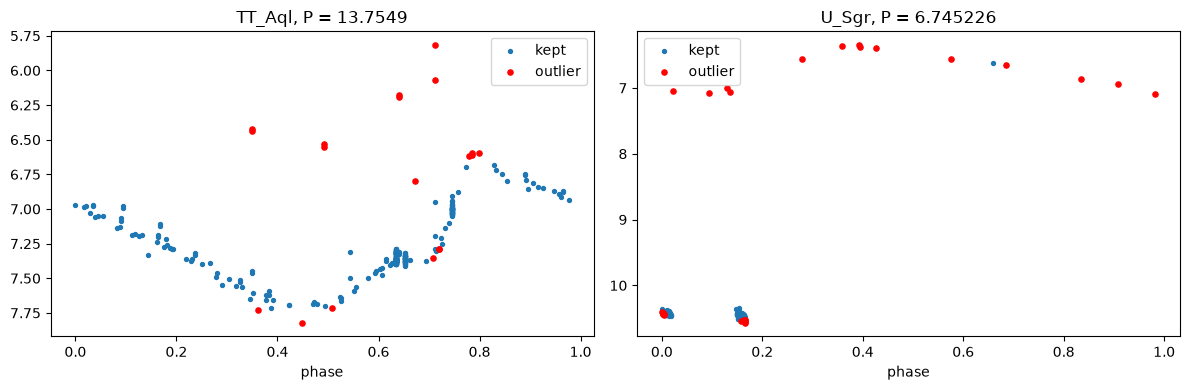

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, auid, nm in [(ax[0], "000-BCF-419", "TT_Aql"), (ax[1], "000-BCC-568", "U_Sgr")]:
    P = targets.loc[targets["AUID"] == auid, "Period"].iloc[0]
    d = flag_outliers(load_star(auid, nm), P)
    a.scatter(d.loc[~d["outlier"], "phase"], d.loc[~d["outlier"], "mag"], s=8, label="kept")
    a.scatter(d.loc[d["outlier"], "phase"], d.loc[d["outlier"], "mag"], s=14, color="red", label="outlier")
    a.invert_yaxis()
    a.set_title(f"{nm}, P = {P}")
    a.set_xlabel("phase")
    a.legend()
plt.tight_layout()
plt.show()

In [13]:
def gross_screen(d, window=1.0):
    med = d["mag"].median()
    return d[(d["mag"] - med).abs() <= window]

rows = []
for _, t in targets[targets["kept"]].iterrows():
    d0 = load_star(t["AUID"], names[t["AUID"]])
    d1 = gross_screen(d0)
    d2 = flag_outliers(d1, t["Period"])
    rows.append({"star": t["Name"], "rows": len(d0), "dropped by window": len(d0) - len(d1),
                 "outliers after": int(d2["outlier"].sum()),
                 "sigma_mad": round(1.4826 * np.median(np.abs(d2["resid"] - np.median(d2["resid"]))), 3)})
print(pd.DataFrame(rows).to_string(index=False))

   star  rows  dropped by window  outliers after  sigma_mad
del Cep   480                  2               1      0.092
eta Aql    84                  0               0      0.066
zet Gem   104                  0               0      0.060
 TT Aql   343                  4              15      0.040
 SU Cyg    84                  0               0      0.054
  W Gem   165                  0               2      0.056
  X Sgr   114                  0               0      0.031
  U Sgr   109                 15               0      0.025
